In [2]:
# Importation des bibliothèques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Chargement de données
df= pd.read_csv("Titanic.csv")
print(df.columns.tolist())

['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [5]:
# Exploration des données
display(df.head(1))
print("Dimension : ", df.shape)
print(f"Dimension : {df.shape}")

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.25,NaN,S


Dimension :  (891, 12)
Dimension : (891, 12)


In [7]:
# Comprendre les types et les statistiques
df.info()
display(df.describe())
display(df.nunique())
print(df["Sex"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


,0
PassengerId,891
Survived,2
Pclass,3
Name,891
Sex,2
Age,88
SibSp,7
Parch,7
Ticket,681
Fare,248


Sex
male      577
female    314
Name: count, dtype: int64


In [ ]:
# Détecter les valeurs manquantes et les doublons
# Nombre de valeurs manquantes par colonne
print(df.isna().sum())
print("*-*-*-*Pourcentage de valeurs manquantes-*-*-*-")
# Pourcentage de valeurs manquantes
print((df.isna().mean()*100).round(1))
#Nombre de lignes dupliquées
print("*-*-*- Nombre de lignes dupliquées  -*-*-*-")
print(df.duplicated().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
*-*-*-*Pourcentage de valeurs manquantes-*-*-*-
PassengerId     0.0
Survived        0.0
Pclass          0.0
Name            0.0
Sex             0.0
Age            19.9
SibSp           0.0
Parch           0.0
Ticket          0.0
Fare            0.0
Cabin          77.1
Embarked        0.2
dtype: float64
*-*-*- Nombre de lignes dupliquées  -*-*-*-
0


In [11]:
#Remplacer l'age par le médiane
df["Age"]=df["Age"].fillna(df["Age"].median())
#Remplacer les ports manquants par la modalité
mode_embarked=df["Embarked"].mode()[0]
df['Embarked']=df['Embarked'].fillna(mode_embarked)

#Verifier le resultat
df[['Age', 'Embarked']].isna().sum()

,0
Age,0
Embarked,0


In [ ]:
#Examiner les doublons
duplicate=df[df.duplicated]

#Supprimer les doublons
df=df.drop_duplicates()

In [12]:
#Sélectionner certaines colonnes
df[['Survived','Sex','Age','Fare']]

,Survived,Sex,Age,Fare
0,0,male,22.0,7.2500
1,1,female,38.0,71.2833
2,1,female,26.0,7.9250
3,1,female,35.0,53.1000
4,0,male,35.0,8.0500
...,...,...,...,...
886,0,male,27.0,13.0000
887,1,female,19.0,30.0000
888,0,female,28.0,23.4500
889,1,male,26.0,30.0000


In [14]:
#Sélectionner certaines colonnes
df[['Survived','Sex','Age','Fare']]
#PAssager de première classe
first_classe=df[df['Pclass']==1]
print(first_classe)
#Combiner plusieurs conditions
women_first=df[(df['Sex']=='female') & (df['Pclass']==1)]
print(women_first)

#Trier par tarif croissant
df.sort_values("Fare",ascending=False)

     PassengerId  Survived  Pclass  \
1              2         1       1   
3              4         1       1   
6              7         0       1   
11            12         1       1   
23            24         1       1   
..           ...       ...     ...   
871          872         1       1   
872          873         0       1   
879          880         1       1   
887          888         1       1   
889          890         1       1   

                                                  Name     Sex   Age  SibSp  \
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
6                              McCarthy, Mr. Timothy J    male  54.0      0   
11                            Bonnell, Miss. Elizabeth  female  58.0      0   
23                        Sloper, Mr. William Thompson    male  28.0      0   
..                                                 ...     ...   ... 

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
679,680,1,1,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,PC 17755,512.3292,B51 B53 B55,C
258,259,1,1,"Ward, Miss. Anna",female,35.0,0,0,PC 17755,512.3292,NaN,C
737,738,1,1,"Lesurer, Mr. Gustave J",male,35.0,0,0,PC 17755,512.3292,B101,C
88,89,1,1,"Fortune, Miss. Mabel Helen",female,23.0,3,2,19950,263.0000,C23 C25 C27,S
438,439,0,1,"Fortune, Mr. Mark",male,64.0,1,4,19950,263.0000,C23 C25 C27,S
...,...,...,...,...,...,...,...,...,...,...,...,...
806,807,0,1,"Andrews, Mr. Thomas Jr",male,39.0,0,0,112050,0.0000,A36,S
815,816,0,1,"Fry, Mr. Richard",male,28.0,0,0,112058,0.0000,B102,S
466,467,0,2,"Campbell, Mr. William",male,28.0,0,0,239853,0.0000,NaN,S
481,482,0,2,"Frost, Mr. Anthony Wood ""Archie""",male,28.0,0,0,239854,0.0000,NaN,S


In [ ]:
#Combiner plusieurs conditions
women_first=df[(df['Sex']=='female') & (df['Pclass']==1)]
women_first


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
11,12,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S
31,32,1,1,"Spencer, Mrs. William Augustus (Marie Eugenie)",female,28.0,1,0,PC 17569,146.5208,B78,C
52,53,1,1,"Harper, Mrs. Henry Sleeper (Myna Haxtun)",female,49.0,1,0,PC 17572,76.7292,D33,C
...,...,...,...,...,...,...,...,...,...,...,...,...
856,857,1,1,"Wick, Mrs. George Dennick (Mary Hitchcock)",female,45.0,1,1,36928,164.8667,NaN,S
862,863,1,1,"Swift, Mrs. Frederick Joel (Margaret Welles Ba...",female,48.0,0,0,17466,25.9292,D17,S
871,872,1,1,"Beckwith, Mrs. Richard Leonard (Sallie Monypeny)",female,47.0,1,1,11751,52.5542,D35,S
879,880,1,1,"Potter, Mrs. Thomas Jr (Lily Alexenia Wilson)",female,56.0,0,1,11767,83.1583,C50,C


In [ ]:
#Trier par tarif croissant
df.sort_values("Fare",ascending=False)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
679,680,1,1,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,PC 17755,512.3292,B51 B53 B55,C
258,259,1,1,"Ward, Miss. Anna",female,35.0,0,0,PC 17755,512.3292,NaN,C
737,738,1,1,"Lesurer, Mr. Gustave J",male,35.0,0,0,PC 17755,512.3292,B101,C
88,89,1,1,"Fortune, Miss. Mabel Helen",female,23.0,3,2,19950,263.0000,C23 C25 C27,S
438,439,0,1,"Fortune, Mr. Mark",male,64.0,1,4,19950,263.0000,C23 C25 C27,S
...,...,...,...,...,...,...,...,...,...,...,...,...
806,807,0,1,"Andrews, Mr. Thomas Jr",male,39.0,0,0,112050,0.0000,A36,S
815,816,0,1,"Fry, Mr. Richard",male,28.0,0,0,112058,0.0000,B102,S
466,467,0,2,"Campbell, Mr. William",male,28.0,0,0,239853,0.0000,NaN,S
481,482,0,2,"Frost, Mr. Anthony Wood ""Archie""",male,28.0,0,0,239854,0.0000,NaN,S


In [ ]:
# Taille de la famille a bord
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

# Taux de survie par classe
survival_by_class = df.groupby("Pclass")["Survived"].mean()
print(survival_by_class)

# Taux de survie par sexe
survival_by_sex = df.groupby("Sex")["Survived"].mean()
print(survival_by_sex)


Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64
1 0.6296296296296297
2 0.47282608695652173
3 0.24236252545824846
Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64


In [ ]:
display(df[["Age", "Fare", "FamilySize"]].describe())

# Taux de survie par classe
print(df.groupby("Pclass")["Survived"].agg(
    ["count", "mean"]
))

# Taux de survie par sexe et classe
survival_table = df.pivot_table(
    values="Survived",
    index="Sex",
    columns="Pclass",
    aggfunc="mean"
)
display(survival_table)


,Age,Fare,FamilySize
count,891.000000,891.000000,891.000000
mean,29.361582,32.204208,1.904602
std,13.019697,49.693429,1.613459
min,0.420000,0.000000,1.000000
25%,22.000000,7.910400,1.000000
50%,28.000000,14.454200,1.000000
75%,35.000000,31.000000,2.000000
max,80.000000,512.329200,11.000000


        count      mean
Pclass                 
1         216  0.629630
2         184  0.472826
3         491  0.242363


Pclass,1,2,3
Sex,,,
female,0.968085,0.921053,0.500000
male,0.368852,0.157407,0.135447


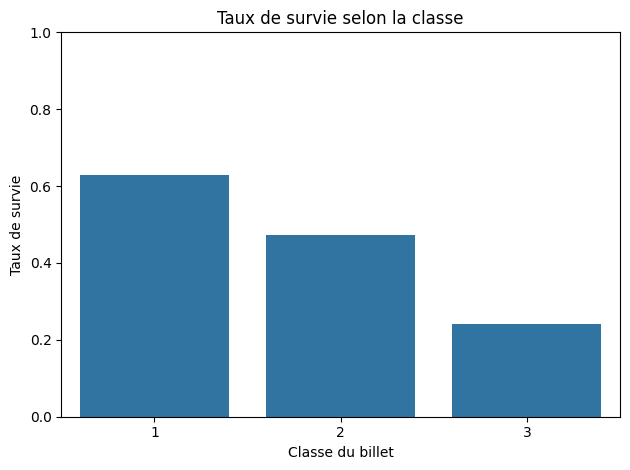

In [ ]:
sns.barplot(data=df, x="Pclass", y="Survived", errorbar=None)
plt.title("Taux de survie selon la classe")
plt.xlabel("Classe du billet")
plt.ylabel("Taux de survie")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

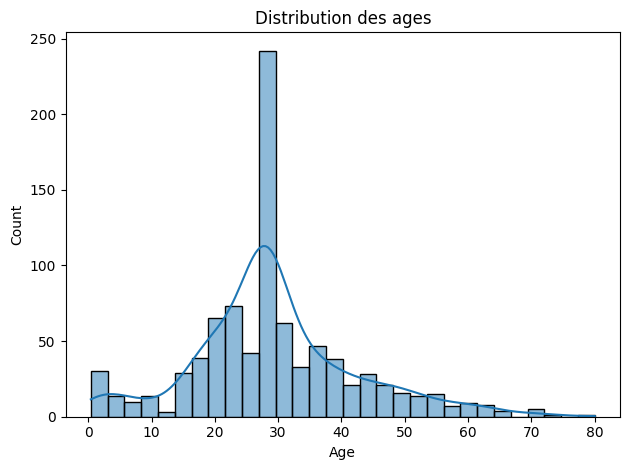

In [ ]:
#Distribution des âges
sns.histplot(data=df, x="Age", kde=True)
plt.title("Distribution des ages")
plt.tight_layout()
plt.show()

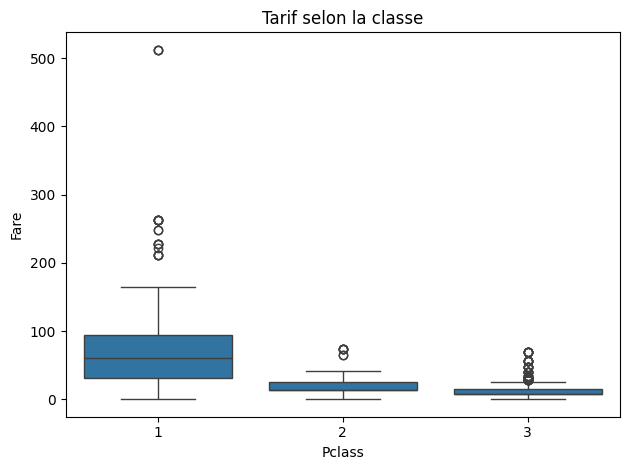

In [ ]:
#Tarif selon la classe
sns.boxplot(data=df, x="Pclass", y="Fare")
plt.title("Tarif selon la classe")
plt.tight_layout()
plt.show()

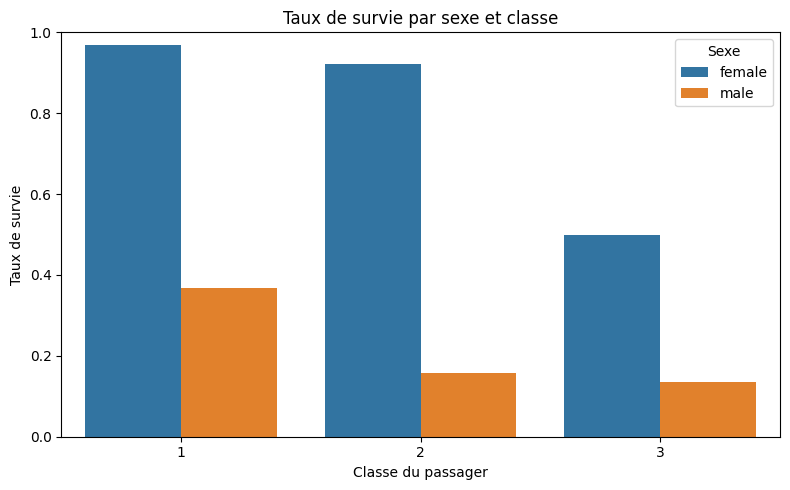

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Pclass",
    y="Survived",
    hue="Sex",
    errorbar=None
)

plt.title("Taux de survie par sexe et classe")
plt.xlabel("Classe du passager")
plt.ylabel("Taux de survie")
plt.ylim(0, 1)
plt.legend(title="Sexe")
plt.tight_layout()
plt.show()